VISIBLE DATA
[[1 0 1 0 1 0]
 [0 1 0 1 0 1]
 [1 1 0 0 1 0]
 [0 0 1 1 0 1]]

HIDDEN PROBABILITIES
[[0.55768918 0.46794129 0.46140931]
 [0.53751194 0.45734389 0.49036071]
 [0.55630286 0.44310504 0.46726274]
 [0.53890831 0.48228706 0.48448107]]

HIDDEN STATES
[[1 1 1]
 [0 1 0]
 [0 1 0]
 [1 1 0]]

RECONSTRUCTED PROBABILITIES
[[0.52513226 0.52634407 0.54679201 0.49033652 0.41590092 0.46851991]
 [0.49654345 0.49414643 0.51917646 0.48841663 0.45231337 0.47470085]
 [0.49654345 0.49414643 0.51917646 0.48841663 0.45231337 0.47470085]
 [0.50896029 0.53217738 0.55839845 0.50197855 0.45831404 0.46070325]]

RECONSTRUCTED DATA
[[0 0 1 1 0 1]
 [1 0 1 0 1 0]
 [1 0 0 1 0 0]
 [0 0 0 0 1 1]]

ENERGY VALUES
Sample 1: Energy = 0.0513
Sample 2: Energy = 0.1710
Sample 3: Energy = 0.2286
Sample 4: Energy = -0.0851

RECONSTRUCTION MSE: 0.2521756368662282


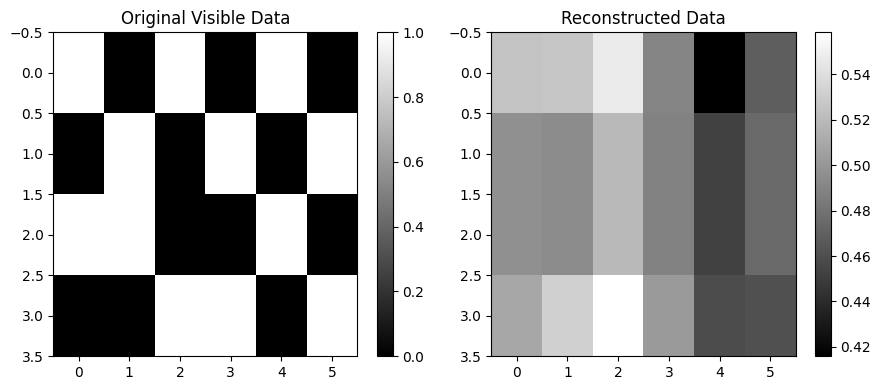

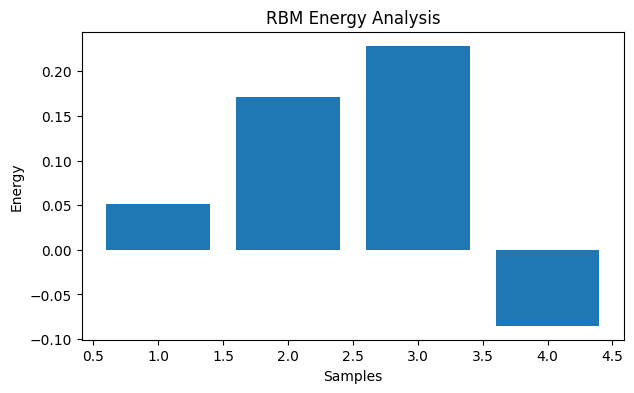

In [17]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.special import expit

np.random.seed(42)

# 1. Define RBM parameters
n_visible = 6
n_hidden = 3

W = np.random.normal(
    0, 0.1,
    (n_visible, n_hidden)
)

visible_bias = np.zeros(n_visible)
hidden_bias = np.zeros(n_hidden)

# 2. Create sample visible data
visible = np.array([
    [1, 0, 1, 0, 1, 0],
    [0, 1, 0, 1, 0, 1],
    [1, 1, 0, 0, 1, 0],
    [0, 0, 1, 1, 0, 1]
])

print("VISIBLE DATA")
print(visible)

# 3. Visible to hidden probability
def visible_to_hidden(v):

    probability = expit(
        np.dot(v, W) + hidden_bias
    )

    return probability

# 4. Hidden to visible probability
def hidden_to_visible(h):

    probability = expit(
        np.dot(h, W.T) + visible_bias
    )

    return probability

# 5. Calculate energy function
def energy(v, h):

    term1 = -np.dot(v, visible_bias)

    term2 = -np.dot(h, hidden_bias)

    term3 = -np.dot(
        np.dot(v, W),
        h
    )

    return term1 + term2 + term3

# 6. Forward propagation
hidden_prob = visible_to_hidden(visible)

hidden_state = (
    np.random.random(hidden_prob.shape)
    < hidden_prob
).astype(int)

print("\nHIDDEN PROBABILITIES")
print(hidden_prob)

print("\nHIDDEN STATES")
print(hidden_state)

# 7. Reconstruct visible layer
reconstructed_prob = hidden_to_visible(
    hidden_state
)

reconstructed_visible = (
    np.random.random(reconstructed_prob.shape)
    < reconstructed_prob
).astype(int)

print("\nRECONSTRUCTED PROBABILITIES")
print(reconstructed_prob)

print("\nRECONSTRUCTED DATA")
print(reconstructed_visible)

# 8. Calculate energy
print("\nENERGY VALUES")

for i in range(len(visible)):

    e = energy(
        visible[i],
        hidden_state[i]
    )

    print(
        f"Sample {i+1}: Energy = {e:.4f}"
    )

# 9. Calculate reconstruction error
mse = np.mean(
    (visible - reconstructed_prob) ** 2
)

print("\nRECONSTRUCTION MSE:", mse)

# 10. Visualize original and reconstructed data
plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)

plt.imshow(
    visible,
    cmap="gray",
    aspect="auto"
)

plt.title("Original Visible Data")

plt.colorbar()

plt.subplot(1, 2, 2)

plt.imshow(
    reconstructed_prob,
    cmap="gray",
    aspect="auto"
)

plt.title("Reconstructed Data")

plt.colorbar()

plt.tight_layout()

plt.show()

# 11. Energy visualization
energies = [
    energy(visible[i], hidden_state[i])
    for i in range(len(visible))
]

plt.figure(figsize=(7, 4))

plt.bar(
    range(1, len(energies) + 1),
    energies
)

plt.xlabel("Samples")

plt.ylabel("Energy")

plt.title("RBM Energy Analysis")

plt.show()